# Section 7 · Retrieve and analyze the results of quantum circuits

Exam weight: 10% of C1000-179 · about 7 of the 68 questions

## Study path

**Core first pass:** Read and save results, retrieve previous jobs, inspect session details, distinguish successful and other final states, and analyse counts and sweep results.

- Core coding practice: **7.1–7.3 and 7.5–7.7**.
- Optional second pass: **7.4 (one status adapter for different job classes) and the exact local JobStatus-printing question.**
- Core review: answer all questions without an optional label.

Run the setup cell, then work through the unmarked examples in order. Complete a practice starter before running its check cell. At an optional block, use its **continue with the core path** link to skip the entire block; the remaining core cells do not depend on it. Notebook tags `study-core` and `study-optional` also identify the two paths; ordinary **Run All** does not filter tags.

Core/optional labels set a learning priority, not a boundary on what the exam may ask. The [official objectives and sample](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400) remain the coverage reference.

**Jump to:** [Retrieve results](#s7-core-3) · [Monitor jobs](#s7-core-32) · [Analyse results](#s7-core-61) · [Review](#s7-core-83)

Official objectives
- 7.1 Retrieve previous experiment results (session / Qiskit Runtime)
- 7.2 Monitor jobs

Topics
- walk a result from `PrimitiveResult` to `PubResult` to `DataBin` to `BitArray` (Sampler) or `evs` / `stds` (Estimator) without guessing field names;
- save a result to disk and load it back with `RuntimeEncoder` / `RuntimeDecoder`;
- find earlier work with `service.job(job_id)`, the filters of `service.jobs(...)`, `job.session_id` and `Session.from_id(...)`, and read `session.details()`;
- monitor a job: the exact status strings, `done()` versus `in_final_state()`, `result(timeout=...)`, `cancel()`, `error_message()`, `metrics()`, `usage_estimation`;
- analyse samples: counts and bit order, marginals, expectation values from counts, parameter sweeps, and merging results of several jobs.

Built from the Qiskit Advocate KR study notebooks `1_Retrieve_Experiment_Results_ko.ipynb` and `2_Monitor_Jobs_KR.ipynb` (with `sampler_result.json`) and the QAMP 2025 tutorial (links in the Sources cell at the end).

The default examples run offline with Runtime `SamplerV2` / `EstimatorV2` on `AerSimulator` (ideal or built from a fake-backend device model). The supplied offline Runtime-job helper supports the monitoring examples. Calls that need an IBM Quantum account are shown in cells guarded by `USE_REAL_HARDWARE = False`.

In [1]:
import json, os, tempfile, typing, datetime
from collections import Counter

import numpy as np
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit import Parameter
from qiskit.primitives import BitArray
from qiskit.providers import JobStatus
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.result import marginal_distribution, sampled_expectation_value
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import (QiskitRuntimeService, SamplerV2, EstimatorV2, Session, Batch,
                                RuntimeJobV2, RuntimeEncoder, RuntimeDecoder)
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

print(f"qiskit {qiskit.__version__} | qiskit-ibm-runtime {qiskit_ibm_runtime.__version__} "
      f"| qiskit-aer {qiskit_aer.__version__}")

USE_REAL_HARDWARE = False   # True only if you have saved an IBM Quantum account

aer = AerSimulator()                                   # ideal local simulator
ideal_sampler = SamplerV2(mode=aer)
ideal_sampler.options.simulator.seed_simulator = 42
ideal_estimator = EstimatorV2(mode=aer)
ideal_estimator.options.simulator.seed_simulator = 42

qiskit 2.0.3 | qiskit-ibm-runtime 0.40.1 | qiskit-aer 0.17.1


### The big picture

Every primitive call hands you a job first and a result later. The job class depends on where the work runs, but the result classes are the same everywhere.

| How the circuit was run | `run()` returns | `job.status()` returns |
|---|---|---|
| `SamplerV2` / `EstimatorV2` on IBM Quantum (`mode=backend`, `Session`, `Batch`) | `RuntimeJobV2` | a string, e.g. `'DONE'` |
| same primitives in local testing mode (`mode=AerSimulator()` or a fake backend) | `LocalRuntimeJob` (a `PrimitiveJob`) | a `JobStatus` enum, e.g. `JobStatus.DONE` |
| `backend.run(circuits)` (for example `AerSimulator`) | `AerJob` (a `JobV1`) | a `JobStatus` enum; `result()` is a `Result`, not a `PrimitiveResult` |

```text
job.result()                      -> PrimitiveResult        (list-like, one entry per PUB, + .metadata)
  result[i]                       -> SamplerPubResult / PubResult   (.data, .metadata)
    result[i].data                -> DataBin
      Sampler:   .<creg name>     -> BitArray  (get_counts, get_bitstrings, get_int_counts, slice_bits, ...)
      Estimator: .evs, .stds      -> numpy arrays shaped like the broadcast PUB
```

Qiskit's reference primitives (`qiskit.primitives`) also return `PrimitiveJob` objects; this notebook uses only `SamplerV2` and `EstimatorV2` from `qiskit_ibm_runtime` on `AerSimulator`.

<a id="s7-core-3"></a>

## 7.1 Retrieve previous experiment results

Retrieving results has three layers: (1) reading the result object you already hold, (2) keeping it on disk, and (3) asking IBM Quantum for jobs and sessions you submitted earlier, possibly from another kernel or another machine.

### 7.1.1 Submit, keep the job ID, read the result

The job ID is the handle for everything in this section. Store it as soon as `run()` returns.

In [2]:
backend = AerSimulator.from_backend(FakeManilaV2())   # Aer with the Manila device model (noise, coupling map)
pm = generate_preset_pass_manager(optimization_level=1, backend=backend, seed_transpiler=11)

bell = QuantumCircuit(2, name="bell"); bell.h(0); bell.cx(0, 1); bell.measure_all()
ghz = QuantumCircuit(3, name="ghz"); ghz.h(0); ghz.cx(0, 1); ghz.cx(1, 2); ghz.measure_all()
isa_bell, isa_ghz = pm.run([bell, ghz])

sampler = SamplerV2(mode=backend)
sampler.options.default_shots = 1000
sampler.options.simulator.seed_simulator = 1234

job = sampler.run([isa_bell, isa_ghz])         # two PUBs in one job
saved_job_id = job.job_id()                    # a plain string: all you need to come back later
print("job id  :", saved_job_id)
print("job type:", type(job).__name__)

result = job.result()                          # blocks until the job is in a final state
print(result)

job id  : f96da89c-246d-40e2-9346-8f322dc8d0c5
job type: LocalRuntimeJob
PrimitiveResult([SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=1000, num_bits=2>)), metadata={'shots': 1000, 'circuit_metadata': {}}), SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=1000, num_bits=3>)), metadata={'shots': 1000, 'circuit_metadata': {}})], metadata={'version': 2})


In [3]:
print("PUB results in this job :", len(result))
pub0 = result[0]
print("type of result[0]       :", type(pub0).__name__)
print("fields in result[0].data:", list(pub0.data.keys()))
print("result[0].metadata      :", pub0.metadata)
print("result.metadata         :", result.metadata)

bits = pub0.data.meas                          # the field is named after the classical register
print("\n", bits)
print("num_shots =", bits.num_shots, "| num_bits =", bits.num_bits, "| shape =", bits.shape)
print("get_counts()        :", bits.get_counts())
print("get_int_counts()    :", bits.get_int_counts())
print("get_bitstrings()[:6]:", bits.get_bitstrings()[:6])

PUB results in this job : 2
type of result[0]       : SamplerPubResult
fields in result[0].data: ['meas']
result[0].metadata      : {'shots': 1000, 'circuit_metadata': {}}
result.metadata         : {'version': 2}

 BitArray(<shape=(), num_shots=1000, num_bits=2>)
num_shots = 1000 | num_bits = 2 | shape = ()
get_counts()        : {'00': 487, '11': 457, '10': 27, '01': 29}
get_int_counts()    : {0: 487, 3: 457, 2: 27, 1: 29}
get_bitstrings()[:6]: ['00', '11', '00', '00', '11', '00']


The `DataBin` field is the name of the classical register, not a fixed word. `measure_all()` creates a register called `meas`, so you read `data.meas`. A circuit built as `QuantumCircuit(2, 2)` has a register called `c`, so you read `data.c`, and `data.meas` raises `AttributeError`. There is no `result.get_counts()` on a `PrimitiveResult`; that method belongs to the old `Result` class returned by `backend.run()`.

Several classical registers. Each register becomes its own `BitArray`. `SamplerPubResult.join_data(names)` glues them into one `BitArray`. The first name in the list supplies the right-most (least significant) bits, which matches Qiskit's little-endian convention.

In [4]:
qr = QuantumRegister(3, "q")
alpha = ClassicalRegister(1, "alpha")
beta = ClassicalRegister(2, "beta")
reg_qc = QuantumCircuit(qr, alpha, beta)
reg_qc.x(0)                        # alpha will always read 1
reg_qc.h(1); reg_qc.cx(1, 2)       # beta reads 00 or 11
reg_qc.measure(0, alpha[0])
reg_qc.measure([1, 2], beta)

reg_result = ideal_sampler.run([reg_qc], shots=400).result()
reg_data = reg_result[0].data
print("fields:", list(reg_data.keys()))
print("alpha :", reg_data.alpha.get_counts())
print("beta  :", reg_data["beta"].get_counts(), "(dictionary-style access also works)")
print("join_data()                 :", reg_result[0].join_data().get_counts())
print('join_data(["beta", "alpha"]):', reg_result[0].join_data(["beta", "alpha"]).get_counts())

fields: ['alpha', 'beta']
alpha : {'1': 400}
beta  : {'00': 209, '11': 191} (dictionary-style access also works)
join_data()                 : {'001': 209, '111': 191}
join_data(["beta", "alpha"]): {'100': 209, '111': 191}


Estimator results. The `DataBin` of an Estimator PUB holds `evs` (expectation values) and `stds` (standard errors), both numpy arrays with the broadcast shape of the PUB. Per the IBM documentation, Estimator results from IBM Quantum hardware also carry `ensemble_standard_error`. The PUB metadata records the requested `target_precision` (and `shots` when the estimate is sampled).

In [5]:
bell_state = QuantumCircuit(2); bell_state.h(0); bell_state.cx(0, 1)   # no measurements for Estimator
est_result = ideal_estimator.run([(bell_state, ["ZZ", "XX", "ZI"])]).result()
est_data = est_result[0].data
print("fields  :", list(est_data.keys()))
print("evs     :", est_data.evs, "| shape", est_data.evs.shape)
print("stds    :", est_data.stds)
print("metadata:", est_result[0].metadata)

fields  : ['evs', 'stds']
evs     : [ 1.          1.         -0.01123047] | shape (3,)
stds    : [0.         0.         0.01562401]
metadata: {'target_precision': 0.015625, 'shots': 4096, 'circuit_metadata': {}}


Chain to memorise: `job.result()[i].data.<register>.get_counts()` for Sampler and `job.result()[i].data.evs` for Estimator. `result[i]` indexes PUBs in submission order, not shots and not circuits inside a PUB.

### Practice 7.1 — Pull numbers out of a Sampler result

The starter cell builds a 3-qubit circuit with `QuantumCircuit(3, 3)` and runs it. From `ex1_result` extract

- `ex1_counts`: the counts dictionary of the first PUB,
- `ex1_num_shots`: the number of shots (an `int`),
- `ex1_p_bit0`: the fraction of shots in which classical bit 0 read `1`.

In [ ]:
ex1_qc = QuantumCircuit(3, 3)
ex1_qc.x(2)
ex1_qc.h(0)
ex1_qc.measure([0, 1, 2], [0, 1, 2])
ex1_result = ideal_sampler.run([ex1_qc], shots=500).result()

ex1_counts = None      # TODO
ex1_num_shots = None   # TODO
ex1_p_bit0 = None      # TODO

In [ ]:
# Run this cell to check your answer
assert isinstance(ex1_counts, dict) and set(ex1_counts) == {"100", "101"}, "expected keys '100' and '101'"
assert ex1_num_shots == 500
_ref = ex1_result[0].data.c.slice_bits([0]).get_counts().get("1", 0) / 500
assert abs(ex1_p_bit0 - _ref) < 1e-12, "classical bit 0 is the RIGHT-most character"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex1_qc = QuantumCircuit(3, 3)
ex1_qc.x(2)
ex1_qc.h(0)
ex1_qc.measure([0, 1, 2], [0, 1, 2])
ex1_result = ideal_sampler.run([ex1_qc], shots=500).result()

ex1_bits = ex1_result[0].data.c              # register created by QuantumCircuit(3, 3) is named "c"
ex1_counts = ex1_bits.get_counts()
ex1_num_shots = ex1_bits.num_shots
ex1_p_bit0 = sum(v for k, v in ex1_counts.items() if k[-1] == "1") / ex1_num_shots
```

The register is `c`, so the field is `data.c`. Bit 0 is the right-most character of each key (little-endian), so the keys are `100` (bit 0 = 0) and `101` (bit 0 = 1). `slice_bits([0])` in the check gives the same number without string handling.

</details>

Q7.1. A circuit is created with `qc = QuantumCircuit(2, 2)`, gates are added, and it ends with `qc.measure([0, 1], [0, 1])`. After `result = SamplerV2(mode=backend).run([isa_qc]).result()`, which expression returns the counts?

A. `result[0].data.meas.get_counts()`

B. `result.get_counts()`

C. `result[0].data.c.get_counts()`

D. `result[0].get_counts()`

<details>
<summary>Show answer</summary>

Answer: C

The default classical register of `QuantumCircuit(2, 2)` is named `c`, and each register becomes a `BitArray` field of the `DataBin`. Option A would be right only for `measure_all()` (register `meas`); it raises `AttributeError` here. `PrimitiveResult` and `SamplerPubResult` have no `get_counts()` method (B, D); that API belongs to the legacy `Result` object from `backend.run()`.

</details>

### 7.1.2 Save results to disk and load them back

A kernel restart wipes results held in memory. `qiskit-ibm-runtime` ships a JSON encoder/decoder pair that understands the primitive containers, numpy arrays and Qiskit objects:

```python
json.dump(result, file, cls=RuntimeEncoder)      # save
result = json.load(file, cls=RuntimeDecoder)     # load (in any later kernel)
```

In [6]:
tmp_dir = tempfile.mkdtemp(prefix="sec7_")
path = os.path.join(tmp_dir, "sampler_result.json")

with open(path, "w") as f:
    json.dump(result, f, cls=RuntimeEncoder)
with open(path) as f:
    print("file starts with:", f.read(90), "...")

with open(path) as f:
    loaded = json.load(f, cls=RuntimeDecoder)
print("loaded type  :", type(loaded).__name__, "/", type(loaded[1]).__name__)
print("same counts  :", loaded[1].data.meas.get_counts() == result[1].data.meas.get_counts())

try:
    json.dumps(result)                          # the standard encoder does not know these classes
except TypeError as err:
    print("plain json   :", err)

file starts with: {"__type__": "PrimitiveResult", "__value__": {"pub_results": [{"__type__": "SamplerPubResu ...
loaded type  : PrimitiveResult / SamplerPubResult
same counts  : True
plain json   : Object of type PrimitiveResult is not JSON serializable


The study group saved a GHZ result as `sampler_result.json` with an earlier `qiskit-ibm-runtime` release. Its text is pasted below so this notebook stays self-contained; it still decodes into the same classes.

In [7]:
STUDY_GROUP_JSON = r"""{"__type__": "PrimitiveResult", "__value__": {"pub_results": [{"__type__": "SamplerPubResult", "__value__": {"data": {"__type__": "DataBin", "__value__": {"field_names": ["meas"], "shape": [], "fields": {"meas": {"__type__": "BitArray", "__value__": {"array": {"__type__": "ndarray", "__value__": "eJydU7tOw0AQ3FQr8RXXXSK5wBEVH0AXlIaCClnEiAIRZIc0ga/gh3FyO7N7LnPKw7e+nd2Znft7fNpsnxdylFPe9ePrkO9T/vluc5Py2344DN3ny37Y9ef4Q/cx9lN8fO+++mm/bG/Xd01qV036TdetG1Wxj0xLy8P5T0ro8rV3UqJqe4vZRiXm2SEtiMoIyl3AUJiIhBMml5+yCojhS+kGp+0ooAVNoTz5Md2ABUj+5BIoJAkkrTP2EJg75RAQkqDA3EEggEWBoxouIPYKacXZCTUFbbYGSh4kObbBY9WsyDqUp+b+AFAIyVR4R7zNWIh2kdnxMGIlMeDQlB6GlWaJnDOZi5cNk4QlOROfm3fPK+HAc/pua89zv/GGVF7lXMI1RMeV9nN7MB5NWpukGn10gq1/DMgppQ=="}, "num_bits": 3}}}}}, "metadata": {"shots": 1024, "circuit_metadata": {}}}}], "metadata": {"version": 2}}}"""

sg_result = json.loads(STUDY_GROUP_JSON, cls=RuntimeDecoder)
print(sg_result)
print("counts:", sg_result[0].data.meas.get_counts())

PrimitiveResult([SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=1024, num_bits=3>)), metadata={'shots': 1024, 'circuit_metadata': {}})], metadata={'version': 2})
counts: {'111': 502, '000': 522}


Encoder for writing, decoder for reading: `json.dump(obj, f, cls=RuntimeEncoder)` and `json.load(f, cls=RuntimeDecoder)`. The same pair works on strings (`json.dumps` / `json.loads`). `RuntimeJobV2.result()` itself decodes the service's payload with `RuntimeDecoder` by default, so a file written this way reloads as the same classes you received.

### Practice 7.2 — Round-trip an Estimator result through JSON text

Serialize `est_result` (the Estimator result from 7.1.1) to a JSON string `ex2_payload`, then decode it into `ex2_restored`. Use the runtime encoder and decoder.

In [ ]:
ex2_payload = None    # TODO: JSON text of est_result
ex2_restored = None   # TODO: object decoded from ex2_payload

In [ ]:
# Run this cell to check your answer
assert isinstance(ex2_payload, str) and '"__type__"' in ex2_payload, "encode with cls=RuntimeEncoder"
assert type(ex2_restored).__name__ == "PrimitiveResult", "decode with cls=RuntimeDecoder"
assert np.allclose(ex2_restored[0].data.evs, est_result[0].data.evs)
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex2_payload = json.dumps(est_result, cls=RuntimeEncoder)
ex2_restored = json.loads(ex2_payload, cls=RuntimeDecoder)
```

`RuntimeEncoder` writes each Qiskit object as `{"__type__": ..., "__value__": ...}`; `RuntimeDecoder` reads those markers and rebuilds `PrimitiveResult`, `PubResult`, `DataBin` and the numpy arrays. Without `cls=RuntimeDecoder` you would get nested plain dictionaries.

</details>

### 7.1.3 Retrieve jobs from IBM Quantum

IBM Quantum stores the results of every job. With an account you can come back to them from any kernel:

| Call | Returns | Notes |
|---|---|---|
| `service.job(job_id)` | `RuntimeJobV2` (for V2 primitive jobs) | the same object type `run()` returned; call `.result()`, `.status()`, ... |
| `service.jobs(...)` | `list[RuntimeJobV2]` | newest first; `limit=10` by default, `limit=None` for all |
| `service.usage()` | `dict` | usage of the active instance |
| `service.delete_job(job_id)` | `None` | deletes the job and its stored result; cannot be undone |

Filters of `service.jobs()` (qiskit-ibm-runtime 0.40):

| Argument | Meaning |
|---|---|
| `limit=10`, `skip=0` | how many jobs, starting where |
| `backend_name="ibm_torino"` | jobs run on one QPU |
| `pending=True / False` | `True`: `QUEUED` and `RUNNING` jobs; `False`: `DONE`, `CANCELLED`, `ERROR` jobs |
| `program_id="sampler"` | `"sampler"` or `"estimator"` |
| `job_tags=["exp-1", "v2"]` | jobs that carry all listed tags (set tags at submission with `sampler.options.environment.job_tags = [...]`, or later with `job.update_tags(...)`) |
| `session_id="..."` | every job of one session or batch |
| `created_after=`, `created_before=` | `datetime.datetime` objects in local time |
| `instance="crn:..."`, `descending=True` | instance filter, sort order |

Use the `ibm_quantum_platform` channel. The legacy `"ibm_quantum"` channel was retired together with the old IBM Quantum Platform on 1 July 2025 (qiskit-ibm-runtime 0.40 still accepts the string, but the service behind it is gone).

In [8]:
if USE_REAL_HARDWARE:
    # One-time setup (stores the credentials locally):
    # QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token="<API key>",
    #                                   instance="<instance CRN or name>", set_as_default=True)
    service = QiskitRuntimeService()   # or QiskitRuntimeService(channel="ibm_quantum_platform", token=..., instance=...)

    old_job = service.job("<job_id you saved>")        # -> RuntimeJobV2
    print(old_job.status(), old_job.creation_date, old_job.primitive_id)
    old_result = old_job.result()

    week_ago = datetime.datetime.now() - datetime.timedelta(days=7)
    finished = service.jobs(limit=5, backend_name="ibm_torino", pending=False, created_after=week_ago)
    tagged = service.jobs(job_tags=["sec7-demo"])      # tags set via sampler.options.environment.job_tags
    done_ids = [j.job_id() for j in finished if j.status() == "DONE"]
else:
    print("USE_REAL_HARDWARE is False: IBM Quantum service calls skipped.")

USE_REAL_HARDWARE is False: IBM Quantum service calls skipped.


`service.jobs()` returns at most 10 jobs unless you pass `limit`. `created_after` is documented as a `datetime.datetime`; version 0.40 happens to parse a string too, but don't rely on it. And `service.job(...)` takes exactly one job ID; there is no `service.get_job`, `service.retrieve_job` or `service.jobs(job_id=...)`.

### 7.1.4 Find a session or batch again

- A Runtime job that ran in a session or batch knows its ID: `job.session_id` (a property, no parentheses).
- `Session.from_id(session_id, service)` rebuilds a `Session` object for an existing session. If the session is still active you can submit more jobs with `SamplerV2(mode=session)`. `Batch` has the same `from_id`, `details()`, `status()` and `usage()` methods.
- `service.jobs(session_id=...)` lists all jobs of that session or batch.

`session.details()` returns a dictionary with exactly these keys (renamed from the REST fields shown in brackets):

| Key | Meaning |
|---|---|
| `id` | session ID |
| `backend_name` | QPU of the session |
| `interactive_timeout` (`interactive_ttl`) | max idle time between jobs before the session is deactivated (s) |
| `max_time` (`max_ttl`) | maximum lifetime of the session (s) |
| `active_timeout` (`active_ttl`) | maximum time the session can stay active (s) |
| `state` | `open`, `active`, `inactive` or `closed` |
| `accepting_jobs` | whether new jobs are accepted |
| `last_job_started`, `last_job_completed` | timestamps of the most recent job |
| `started_at`, `activated_at`, `closed_at` | lifecycle timestamps |
| `mode` | `dedicated` (session) or `batch` |
| `usage_time` (`elapsed_time`) | usage in seconds |

`session.status()` condenses `state` and `accepting_jobs` into one string: `'Pending'` (open or inactive), `'In progress, accepting new jobs'`, `'In progress, not accepting new jobs'`, or `'Closed'`. `session.usage()` returns the usage in seconds.

In [9]:
if USE_REAL_HARDWARE:
    sid = old_job.session_id                          # property of RuntimeJobV2
    session = Session.from_id(sid, service)           # classmethod: (session_id, service)
    info = session.details()
    print(info["state"], info["accepting_jobs"], info["last_job_started"], info["usage_time"])
    print(session.status(), session.usage())
    session_jobs = service.jobs(session_id=sid, limit=None)
    session.close()                                   # stop accepting jobs; queued jobs still finish
else:
    print("USE_REAL_HARDWARE is False: Session.from_id skipped.")

# Local testing mode accepts Session/Batch but ignores them: there is no server-side session.
with Session(backend=backend) as local_session:
    local_job = SamplerV2(mode=local_session).run([isa_bell], shots=200)
    print("local session_id:", local_session.session_id,
          "| details():", local_session.details(), "| status():", local_session.status())
    print("session.backend() returns a", type(local_session.backend()).__name__,
          "->", local_session.backend())
    print("local job.session_id equals its job_id:", local_job.session_id == local_job.job_id())

USE_REAL_HARDWARE is False: Session.from_id skipped.
local session_id: None | details(): None | status(): None
session.backend() returns a str -> aer_simulator_from(fake_manila)
local job.session_id equals its job_id: True


In qiskit-ibm-runtime 0.40 the constructor is `Session(backend, max_time=None)`; there is no `service=` argument (the backend already knows its service), and primitives take `mode=session` (the old `session=` keyword is gone). `session.backend()` returns the backend name (a string), while `job.backend()` returns a backend object.

Q7.2. You print `session.details()` for a session that ran two jobs. Which two keys are in the dictionary? (Select two.)

A. `'last_job_completed'`

B. `'max_ttl'`

C. `'queue_position'`

D. `'accepting_jobs'`

E. `'num_jobs'`

<details>
<summary>Show answer</summary>

Answer: A, D

`details()` returns `id`, `backend_name`, `interactive_timeout`, `max_time`, `active_timeout`, `state`, `accepting_jobs`, `last_job_started`, `last_job_completed`, `started_at`, `closed_at`, `activated_at`, `mode` and `usage_time`. `max_ttl` (B) is the raw REST field that `details()` renames to `max_time`; `queue_position` and `num_jobs` are not reported.

</details>

<a id="s7-core-32"></a>

## 7.2 Monitor jobs

### 7.2.1 Job lifecycle and the exact status values

`RuntimeJobV2.status()` returns a plain string from a fixed set. The Workloads page of IBM Quantum Platform and the REST API use different words for the same states:

| Platform UI (per the IBM documentation) | REST `state.status` | `RuntimeJobV2.status()` | Final? |
|---|---|---|---|
| (before the first query) | | `'INITIALIZING'` | no |
| Pending | `Queued` | `'QUEUED'` | no |
| In progress | `Running` | `'RUNNING'` | no |
| Completed | `Completed` | `'DONE'` | yes |
| Failed | `Failed` | `'ERROR'` | yes |
| Canceled | `Cancelled` | `'CANCELLED'` | yes |

A job that the service stops for exceeding its maximum execution time is reported as `'ERROR'`, and its `result()` raises `RuntimeJobMaxTimeoutError`. Per the IBM documentation, a job shows `RUNNING` as soon as its classical pre-processing starts, not when the QPU starts, so a long `RUNNING` phase in job or batch mode does not add usage. Local jobs use the `qiskit.providers.JobStatus` enum instead, which also has a `VALIDATING` member.

In [10]:
from qiskit_ibm_runtime import runtime_job_v2
print("RuntimeJobV2.status() values:", typing.get_args(runtime_job_v2.JobStatus))
print("RuntimeJobV2.JOB_FINAL_STATES:", RuntimeJobV2.JOB_FINAL_STATES)
print("qiskit.providers.JobStatus  :", [s.name for s in JobStatus])
print("JobStatus.DONE == 'DONE'    :", JobStatus.DONE == "DONE", "| JobStatus.DONE.name == 'DONE':", JobStatus.DONE.name == "DONE")

RuntimeJobV2.status() values: ('INITIALIZING', 'QUEUED', 'RUNNING', 'CANCELLED', 'DONE', 'ERROR')
RuntimeJobV2.JOB_FINAL_STATES: ('DONE', 'CANCELLED', 'ERROR')
qiskit.providers.JobStatus  : ['INITIALIZING', 'QUEUED', 'VALIDATING', 'RUNNING', 'CANCELLED', 'DONE', 'ERROR']
JobStatus.DONE == 'DONE'    : False | JobStatus.DONE.name == 'DONE': True


`job.status() == "COMPLETED"` is never true in Qiskit: `COMPLETED` is the REST/UI word, Qiskit says `'DONE'`. For local jobs the status is an enum, so compare with `JobStatus.DONE` or `status.name == "DONE"`; comparing the enum with the string `'DONE'` gives `False`.

### 7.2.2 What you can ask a job

| Member | `RuntimeJobV2` returns | Notes |
|---|---|---|
| `job_id()` | `str` | method, not property |
| `status()` | `str` (see table above) | asks the service on each call until the job is final, then returns the cached value |
| `done()` / `running()` / `cancelled()` / `errored()` | `bool` | `done()` is `True` only for `'DONE'` |
| `in_final_state()` | `bool` | `True` for `'DONE'`, `'CANCELLED'` or `'ERROR'` |
| `result(timeout=None, decoder=None)` | `PrimitiveResult` | blocks; raises `RuntimeJobTimeoutError` when the client-side `timeout` (s) runs out, `RuntimeJobFailureError` if the job failed, `RuntimeJobMaxTimeoutError` if the service stopped it for exceeding its maximum execution time (not a subclass of `RuntimeJobFailureError`), `RuntimeInvalidStateError` if it was cancelled |
| `wait_for_final_state(timeout=None)` | `None` | blocks without fetching the result (polls every 0.1 s) |
| `cancel()` | `None` | queued or running jobs; cannot be resumed |
| `error_message()` | `str` or `None` | reason for a failed job |
| `metrics()` | `dict` | includes `timestamps` (created / running / finished) and `usage` |
| `usage()` | `float` | QPU usage in seconds (the `quantum_seconds` entry of `metrics()['usage']`) |
| `usage_estimation` | `dict` | property: `{'quantum_seconds': ...}` estimated before running |
| `logs()` | `str` | available after the job finishes |
| `creation_date` | `datetime` | property, local time |
| `session_id`, `tags`, `primitive_id`, `inputs` | | properties |
| `update_tags(new_tags)` | `list[str]` | replaces the tags |
| `backend()`, `properties()` | backend object, calibration data | `properties()` gives T1, T2, errors at execution time |

Older material also lists `queue_position()` and `queue_info()`; they are not methods of `RuntimeJobV2`. Compare the two job classes you meet in this notebook directly:

In [11]:
members = ["job_id", "status", "done", "running", "cancelled", "errored", "in_final_state", "result",
           "wait_for_final_state", "cancel", "error_message", "metrics", "usage", "usage_estimation",
           "logs", "creation_date", "session_id", "tags", "update_tags", "backend", "queue_position"]
local_cls = type(job)
print(f"{'member':22s}{'RuntimeJobV2':>14s}{local_cls.__name__:>18s}")
for m in members:
    print(f"{m:22s}{str(hasattr(RuntimeJobV2, m)):>14s}{str(hasattr(local_cls, m)):>18s}")

member                  RuntimeJobV2   LocalRuntimeJob
job_id                          True              True
status                          True              True
done                            True              True
running                         True              True
cancelled                       True              True
errored                         True             False
in_final_state                  True              True
result                          True              True
wait_for_final_state            True             False
cancel                          True              True
error_message                   True              True
metrics                         True              True
usage                           True              True
usage_estimation                True             False
logs                            True             False
creation_date                   True              True
session_id                      True              True
tags      

### 7.2.3 Watch a `RuntimeJobV2` offline

> **Study priority.** Supplied teaching infrastructure: run the following helper cell unchanged for the monitoring demos and Practices 7.3 and 7.5. You do not need to memorise or reimplement OfflineRuntimeAPI or the private client fields. Focus on the public job methods exercised below.

`RuntimeJobV2` talks to IBM Quantum through an API client object. The helper below replaces only that client with a scripted stand-in, so the real `RuntimeJobV2` code (status mapping, polling, time-outs, exceptions, result decoding) runs without an account. The stand-in answers with the fields the client reads from the service (`state.status`, `state.reason`, `created`, `session_id`, `tags`, `estimated_running_time_seconds`). It is a teaching aid; you never need it with a real account.

In [12]:
class OfflineRuntimeAPI:
    """Scripted stand-in for the IBM Quantum job endpoints (offline teaching aid)."""

    def __init__(self, states, result=None, reason=None, reason_code=None, session_id=None, tags=None,
                 created="2026-09-30T08:00:00Z"):
        self.states, self.i = list(states), 0            # server-side words, e.g. "Queued"
        self.result, self.reason, self.reason_code = result, reason, reason_code
        self.session_id, self.tags, self.created = session_id, list(tags or []), created

    def job_get(self, job_id, exclude_params=True):       # GET  /v1/jobs/{id}
        state = self.states[min(self.i, len(self.states) - 1)]
        self.i += 1
        body = {"id": job_id, "status": state, "state": {"status": state}, "created": self.created,
                "session_id": self.session_id, "tags": self.tags,
                "estimated_running_time_seconds": 2.1}
        if state in ("Failed", "Cancelled") and self.reason:
            body["state"]["reason"] = self.reason
            if self.reason_code:
                body["state"]["reasonCode"] = self.reason_code
        return body

    def job_results(self, job_id):                        # GET  /v1/jobs/{id}/results
        return json.dumps(self.result, cls=RuntimeEncoder) if self.result is not None else ""

    def job_cancel(self, job_id):                         # POST /v1/jobs/{id}/cancel
        self.states, self.i = ["Cancelled"], 0

    def job_metadata(self, job_id):                       # GET  /v1/jobs/{id}/metrics
        return {"timestamps": {"created": self.created, "running": "2026-09-30T08:00:05Z",
                               "finished": "2026-09-30T08:00:09Z"},
                "usage": {"quantum_seconds": 2, "seconds": 2}}

    def job_logs(self, job_id):                           # GET  /v1/jobs/{id}/logs
        return "(offline stand-in: no logs)"

    def update_tags(self, job_id, tags):                  # PUT  /v1/jobs/{id}/tags
        self.tags = list(tags)
        return type("Response", (), {"status_code": 204})()


def make_offline_job(states, result=None, program_id="sampler", **kwargs):
    """A real RuntimeJobV2 whose server replies follow `states`, one reply per status query."""
    api = OfflineRuntimeAPI(states, result=result, **kwargs)
    return RuntimeJobV2(backend=None, api_client=api, job_id=f"offline-{program_id}-0001",
                        program_id=program_id, service=None, creation_date=api.created,
                        session_id=kwargs.get("session_id"), tags=kwargs.get("tags"))

from qiskit_ibm_runtime.exceptions import (RuntimeJobTimeoutError, RuntimeJobFailureError,
                                           RuntimeJobMaxTimeoutError, RuntimeInvalidStateError)

In [13]:
# Polling until the job is final: call status() once per iteration, stop on a final state.
watch_job = make_offline_job(["Queued", "Queued", "Running", "Running", "Completed"],
                             result=result, tags=["sec7-demo"])
print(watch_job, "| initial value (private attribute, shown once):", watch_job._status)

history = []
while True:
    s = watch_job.status()
    history.append(s)
    if s in RuntimeJobV2.JOB_FINAL_STATES:
        break
print("status history:", history)
print("done():", watch_job.done(), "| in_final_state():", watch_job.in_final_state(),
      "| running():", watch_job.running(), "| errored():", watch_job.errored())

watch_result = watch_job.result()          # decoded with RuntimeDecoder
print("result type:", type(watch_result).__name__, "| GHZ counts:", watch_result[1].data.meas.get_counts())

<RuntimeJobV2('offline-sampler-0001', 'sampler')> | initial value (private attribute, shown once): INITIALIZING
status history: ['QUEUED', 'QUEUED', 'RUNNING', 'RUNNING', 'DONE']
done(): True | in_final_state(): True | running(): False | errored(): False
result type: PrimitiveResult | GHZ counts: {'000': 460, '100': 48, '011': 41, '111': 396, '010': 10, '001': 15, '101': 13, '110': 17}


In [14]:
# Time-outs and cancellation: result(timeout=...) stops waiting, it does not cancel the job.
stuck = make_offline_job(["Queued"], result=result)
try:
    stuck.result(timeout=0.3)
except RuntimeJobTimeoutError as err:
    print("RuntimeJobTimeoutError:", err)
print("status after the time-out:", stuck.status())

stuck.cancel()
print("after cancel():", stuck.status(), "| cancelled():", stuck.cancelled(),
      "| in_final_state():", stuck.in_final_state(), "| done():", stuck.done())
try:
    stuck.result()
except RuntimeInvalidStateError as err:
    print("RuntimeInvalidStateError:", err)

RuntimeJobTimeoutError: 'Timed out waiting for job to complete after 0.3 secs.'
status after the time-out: QUEUED
after cancel(): CANCELLED | cancelled(): True | in_final_state(): True | done(): False
RuntimeInvalidStateError: 'Unable to retrieve result for job offline-sampler-0001. Job was cancelled.'


In [15]:
# A failed job: error_message() explains the failure and result() raises.
failing = make_offline_job(["Running", "Failed"],
                           reason="The instruction h on qubits (0,) is not supported by the target system.")
failing.wait_for_final_state()
print("status:", failing.status(), "| errored():", failing.errored(), "| in_final_state():", failing.in_final_state())
print("error_message():", failing.error_message())
try:
    failing.result()
except RuntimeJobFailureError as err:
    print("RuntimeJobFailureError:", err)

# The service stops a job that exceeds its maximum execution time (reason code 1305; scripted here).
too_long = make_offline_job(["Running", "Cancelled"], reason="(scripted) exceeded max execution time", reason_code=1305)
too_long.wait_for_final_state()
print("status:", too_long.status(), "| cancelled():", too_long.cancelled())
try:
    too_long.result()
except RuntimeJobMaxTimeoutError as err:
    print("RuntimeJobMaxTimeoutError:", err,
          "| subclass of RuntimeJobFailureError?", issubclass(RuntimeJobMaxTimeoutError, RuntimeJobFailureError))

status: ERROR | errored(): True | in_final_state(): True
error_message(): Job offline-sampler-0001 has failed:
The instruction h on qubits (0,) is not supported by the target system.
RuntimeJobFailureError: 'Unable to retrieve job result. The instruction h on qubits (0,) is not supported by the target system.'


status: ERROR | cancelled(): False
RuntimeJobMaxTimeoutError: 'Error code 1305; (scripted) exceeded max execution time' | subclass of RuntimeJobFailureError? False


In [16]:
# Bookkeeping: dates, estimates, metrics and tags.
info_job = make_offline_job(["Completed"], result=result, tags=["sec7-demo"])
print("creation_date (UTC):", info_job.creation_date.astimezone(datetime.timezone.utc))
print("usage_estimation   :", info_job.usage_estimation)
print("metrics() keys     :", list(info_job.metrics()), "->", info_job.metrics()["timestamps"])
print("tags               :", info_job.tags)
print("update_tags(...)   :", sorted(info_job.update_tags(["sec7-demo", "reviewed"])))
print("primitive_id       :", info_job.primitive_id)

creation_date (UTC): 2026-09-30 08:00:00+00:00
usage_estimation   : {'quantum_seconds': 2.1}
metrics() keys     : ['timestamps', 'usage'] -> {'created': '2026-09-30T08:00:00Z', 'running': '2026-09-30T08:00:05Z', 'finished': '2026-09-30T08:00:09Z'}
tags               : ['sec7-demo']
update_tags(...)   : ['reviewed', 'sec7-demo']
primitive_id       : sampler


`result()` is blocking. To poll without blocking, call `status()` (or `done()` / `in_final_state()`) in a loop; to block with a limit, use `result(timeout=s)` or `wait_for_final_state(timeout=s)`, both of which raise `RuntimeJobTimeoutError` when this client-side limit runs out and leave the job untouched. Do not confuse it with `RuntimeJobMaxTimeoutError`, raised by `result()` when the service stopped the job at its maximum execution time.

`in_final_state()` is also `True` for failed and cancelled jobs. Only `done()` (or `status() == 'DONE'`) tells you that a result exists.

### 7.2.4 Local testing mode and `backend.run()` jobs

Local jobs finish almost immediately and carry fewer features: `status()` is a `JobStatus` enum, `result()` takes no `timeout`, `usage()` is `0`, `error_message()` is `''`, and there is no `logs()`, `tags` or `usage_estimation`. With a fake backend as `mode`, local testing mode checks each circuit against the device, so `run()` raises `IBMInputValueError` for a non-ISA circuit before any job exists (shown below). With `AerSimulator.from_backend(...)` as `mode` there is no such check at submission: the job is created, ends in `JobStatus.ERROR`, and `result()` raises `AerError: unknown instruction`.

In [17]:
print("status():", job.status(), "| done():", job.done(), "| in_final_state():", job.in_final_state())
print("metrics():", {k: v for k, v in job.metrics().items() if k != "timestamps"}, "+ timestamps")
print("usage():", job.usage(), "| error_message():", repr(job.error_message()), "| primitive_id:", job.primitive_id)

try:
    SamplerV2(mode=FakeManilaV2()).run([bell])   # fake backend as device model; 'bell' was never transpiled
except Exception as err:
    print(type(err).__name__, "raised by run():", str(err)[:75], "...")

aer_job = AerSimulator(seed_simulator=3).run(bell, shots=200)   # legacy backend.run() path
aer_result = aer_job.result()
print(type(aer_job).__name__, aer_job.status(), "->", type(aer_result).__name__, aer_result.get_counts())

status(): JobStatus.DONE | done(): True | in_final_state(): True
metrics(): {'bss': {'seconds': 0}, 'usage': {'quantum_seconds': 0, 'seconds': 0}} + timestamps
usage(): 0 | error_message(): '' | primitive_id: sampler
IBMInputValueError raised by run(): 'The instruction h on qubits (0,) is not supported by the target system. Ci ...
AerJob JobStatus.DONE -> Result {'00': 104, '11': 96}


### Practice 7.3 — A polling helper

Write `ex3_wait(job, poll_interval=0.0)` that calls `job.status()` once per iteration, appends each value to a list, stops as soon as the status is final (`'DONE'`, `'CANCELLED'` or `'ERROR'`), and returns the list. Use `time.sleep(poll_interval)` between queries. The check runs it on offline Runtime jobs.

In [ ]:
import time

def ex3_wait(job, poll_interval=0.0):
    history = []
    # TODO: poll job.status() until it is final
    return history

In [ ]:
# Run this cell to check your answer
_h = ex3_wait(make_offline_job(["Queued", "Running", "Running", "Completed"], result=result))
assert _h == ["QUEUED", "RUNNING", "RUNNING", "DONE"], f"got {_h}"
_h = ex3_wait(make_offline_job(["Queued", "Failed"], reason="demo"))
assert _h == ["QUEUED", "ERROR"], f"got {_h}"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
import time

def ex3_wait(job, poll_interval=0.0):
    history = []
    while True:
        s = job.status()
        history.append(s)
        if s in ("DONE", "CANCELLED", "ERROR"):
            return history
        time.sleep(poll_interval)
```

The service words `Queued`, `Running`, `Completed`, `Failed` come back from `status()` as `'QUEUED'`, `'RUNNING'`, `'DONE'`, `'ERROR'`. A loop that stops only on `'DONE'` would never end for a failed or cancelled job, which is why the final-state set has three members.

</details>

### Practice 7.4 — One status name for every job type

> **Optional extension.** Practice 7.4: adapt different job-status types. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s7-resume-51). Later core code does not require this block.

Code that must handle both local jobs (enum) and Runtime jobs (string) needs one comparison. Write `ex4_status_name(status)` that returns the upper-case name as a `str` for either kind: `JobStatus.DONE` gives `'DONE'`, `'RUNNING'` gives `'RUNNING'`.

In [ ]:
def ex4_status_name(status):
    return None   # TODO

In [ ]:
# Run this cell to check your answer
assert ex4_status_name(JobStatus.DONE) == "DONE"
assert ex4_status_name(JobStatus.CANCELLED) == "CANCELLED"
assert ex4_status_name("RUNNING") == "RUNNING"
assert ex4_status_name(job.status()) == "DONE"                                     # local job (enum)
assert ex4_status_name(make_offline_job(["Completed"], result=result).status()) == "DONE"   # Runtime job (str)
print("Correct!")

<details>
<summary>Show solution</summary>

```python
def ex4_status_name(status):
    return status.name if isinstance(status, JobStatus) else str(status).upper()
```

`JobStatus` members have a `.name` (`'DONE'`) and a descriptive `.value` (`'job has successfully run'`); `str(JobStatus.DONE)` is `'JobStatus.DONE'`, so neither `.value` nor `str()` gives the short name. Runtime statuses are already strings.

</details>

<a id="s7-resume-51"></a>

### Practice 7.5 — Collect a result safely

Write `ex5_collect(job)` for Runtime jobs that waits for a final state and returns a tuple:

- `("DONE", <PrimitiveResult>)` for a successful job,
- `("ERROR", <error message string>)` for a failed job,
- `("CANCELLED", None)` for a cancelled job.

It must not raise for failed or cancelled jobs.

In [ ]:
def ex5_collect(job):
    return None   # TODO

In [ ]:
# Run this cell to check your answer
_ok = ex5_collect(make_offline_job(["Running", "Completed"], result=result))
assert isinstance(_ok, tuple), "return a tuple"
assert _ok[0] == "DONE" and type(_ok[1]).__name__ == "PrimitiveResult"
_bad = ex5_collect(make_offline_job(["Running", "Failed"], reason="bad ISA"))
assert _bad[0] == "ERROR" and "bad ISA" in _bad[1]
_c = make_offline_job(["Queued"]); _c.cancel()
assert ex5_collect(_c) == ("CANCELLED", None)
print("Correct!")

<details>
<summary>Show solution</summary>

```python
def ex5_collect(job):
    job.wait_for_final_state()
    s = job.status()
    if s == "DONE":
        return ("DONE", job.result())
    if s == "ERROR":
        return ("ERROR", job.error_message())
    return ("CANCELLED", None)
```

Calling `result()` directly would raise `RuntimeJobFailureError` for the failed job and `RuntimeInvalidStateError` for the cancelled one. Checking the final status first (or catching those exceptions) keeps a batch-processing script alive.

</details>

Q7.3. A Runtime job has finished successfully. What does this code print?

```python
print(job.status(), job.in_final_state(), job.status() == "COMPLETED")
```

A. `COMPLETED True True`

B. `DONE True False`

C. `JobStatus.DONE True False`

D. `DONE False False`

<details>
<summary>Show answer</summary>

Answer: B

`RuntimeJobV2.status()` returns the string `'DONE'` (the service's `Completed` is mapped to it), and `DONE` is a final state. `'COMPLETED'` never appears in Qiskit. `JobStatus.DONE` (C) is what a local job prints.

</details>

Q7.4. A Runtime job was cancelled while queued. Which statement is true?

A. `job.done()` returns `True` because the job reached a final state.

B. `job.result()` returns an empty `PrimitiveResult`.

C. `job.status()` returns `'ERROR'`.

D. `job.in_final_state()` returns `True` and `job.result()` raises an exception.

<details>
<summary>Show answer</summary>

Answer: D

`'CANCELLED'` is one of the three final states, so `in_final_state()` is `True`, but `done()` is `True` only for `'DONE'`. `result()` on a cancelled job raises `RuntimeInvalidStateError`; there is no empty result. The status is `'CANCELLED'`, not `'ERROR'` (the only exception is a job stopped for exceeding its maximum execution time).

</details>

<a id="s7-core-61"></a>

## 7.3 Analyze the results

The section title says retrieve and analyze. The exam checks that you can turn a `BitArray` or `evs` array into the number you need.

### 7.3.1 Bit order

Qiskit is little-endian: classical bit 0 is the right-most character of a bitstring, and `get_int_counts()` reads the string as a binary number.

In [18]:
order_qc = QuantumCircuit(3); order_qc.x(0); order_qc.measure_all()
order_bits = ideal_sampler.run([order_qc], shots=10).result()[0].data.meas
print("X on qubit 0 ->", order_bits.get_counts(), "| as integers:", order_bits.get_int_counts())

X on qubit 0 -> {'001': 10} | as integers: {1: 10}


### 7.3.2 Marginals and post-selection

To keep only some bits use `BitArray.slice_bits(indices)` on the result, or `qiskit.result.marginal_distribution(counts, indices)` on a plain counts dictionary. Both index bits little-endian and keep the order of the remaining bits. `BitArray.postselect(indices, selection)` keeps only the shots whose bits match.

In [19]:
ghz_bits = result[1].data.meas                  # GHZ PUB from 7.1.1 (noisy fake backend)
ghz_counts = ghz_bits.get_counts()
print("full counts                :", ghz_counts)
print("slice_bits([0]).get_counts:", ghz_bits.slice_bits([0]).get_counts())
print("slice_bits([0, 2])         :", ghz_bits.slice_bits([0, 2]).get_counts())
print("marginal_distribution(...) :", marginal_distribution(ghz_counts, indices=[0, 2]))
kept = ghz_bits.postselect([0], [1])            # keep shots with bit 0 == 1
print(f"postselect bit0=1: {kept.num_shots} of {ghz_bits.num_shots} shots ->", kept.get_counts())

full counts                : {'000': 460, '100': 48, '011': 41, '111': 396, '010': 10, '001': 15, '101': 13, '110': 17}
slice_bits([0]).get_counts: {'0': 535, '1': 465}
slice_bits([0, 2])         : {'00': 470, '10': 65, '01': 56, '11': 409}
marginal_distribution(...) : {'01': 56, '00': 470, '11': 409, '10': 65}
postselect bit0=1: 465 of 1000 shots -> {'011': 41, '111': 396, '001': 15, '101': 13}


Q7.5. What does this code print?

```python
from qiskit.result import marginal_distribution
print(sorted(marginal_distribution({"011": 600, "100": 400}, indices=[0]).items()))
```

A. `[('0', 600), ('1', 400)]`

B. `[('0', 400), ('1', 600)]`

C. `[('01', 600), ('10', 400)]`

D. `[('1', 1000)]`

<details>
<summary>Show answer</summary>

Answer: B

Index 0 is the right-most character: `'011'` has bit 0 = `1`, `'100'` has bit 0 = `0`. Option A reads the left-most character (big-endian), which is the classic mistake. Marginalising to one index gives one-character keys, so C is wrong. (`sorted` is used because the dictionary's key order is not guaranteed.)

</details>

### 7.3.3 Expectation values from samples

For diagonal observables (strings of `I` and `Z`) the counts are enough:

$$\langle Z_{i_1}\cdots Z_{i_k}\rangle = \sum_x p(x)\,(-1)^{x_{i_1}+\dots+x_{i_k}}.$$

`qiskit.result.sampled_expectation_value(counts, "ZZ")` does this for one operator, `BitArray.expectation_values([...])` for many. Pauli labels are little-endian too: in `"ZI"` the `Z` acts on qubit 1. For `X` or `Y` terms, rotate the measurement basis first (append `H` for `X`, `S†` then `H` for `Y`) and then evaluate `Z`; `sampled_expectation_value` refuses non-diagonal operators.

In [20]:
bell_bits = result[0].data.meas
exact = [Statevector(bell_state).expectation_value(SparsePauliOp(p)).real for p in ["ZZ", "ZI", "IZ"]]
print("sampled <ZZ>          :", sampled_expectation_value(bell_bits.get_counts(), "ZZ"))
print("BitArray ZZ, ZI, IZ   :", bell_bits.expectation_values(["ZZ", "ZI", "IZ"]))
print("exact (Statevector)    :", np.round(exact, 3))
print('counts {"01": 100}: <IZ> =', sampled_expectation_value({"01": 100}, "IZ"),
      '| <ZI> =', sampled_expectation_value({"01": 100}, "ZI"))
try:
    sampled_expectation_value(bell_bits.get_counts(), "XX")
except Exception as err:
    print(type(err).__name__, ":", err)

sampled <ZZ>          : 0.888
BitArray ZZ, ZI, IZ   : [0.888 0.032 0.028]
exact (Statevector)    : [1. 0. 0.]
counts {"01": 100}: <IZ> = -1.0 | <ZI> = 1.0
QiskitError : 'Input operator XX is not diagonal'


To read an expectation value off Sampler counts by hand: find the bits the Pauli string touches (labels are little-endian, the right-most letter is qubit 0), take the parity of those bits for each outcome, and average $(-1)^{\text{parity}}$ weighted by the counts. `sampled_expectation_value` does exactly this for strings of `I` and `Z`.

### 7.3.4 Parameter sweeps and result shapes

A PUB with several parameter sets returns a `BitArray` whose `shape` is the shape of the sweep. `get_counts(loc)` selects one setting; `get_counts()` with no argument merges all settings into one dictionary. `num_shots` is per setting. For the Estimator, `evs` has the broadcast shape of observables and parameter values.

In [21]:
theta = Parameter("θ")
sweep_qc = QuantumCircuit(1); sweep_qc.ry(theta, 0); sweep_qc.measure_all()
angles = np.linspace(0, np.pi, 5)

sweep_bits = ideal_sampler.run([(sweep_qc, angles)], shots=1000).result()[0].data.meas
print("BitArray shape:", sweep_bits.shape, "| shots per setting:", sweep_bits.num_shots)
for i, a in enumerate(angles):
    p1 = sweep_bits.get_counts(i).get("1", 0) / sweep_bits.num_shots
    print(f"  θ = {a:.3f}: P(1) = {p1:.3f}   exact sin²(θ/2) = {np.sin(a / 2) ** 2:.3f}")
print("get_counts() merges all 5 settings:", sweep_bits.get_counts())

sweep_state = QuantumCircuit(1); sweep_state.ry(theta, 0)
sweep_evs = ideal_estimator.run([(sweep_state, [["Z"], ["X"]], angles)]).result()[0].data.evs
print("Estimator evs shape (observables (2,1) x values (5,)):", sweep_evs.shape)
print(np.round(sweep_evs, 2))

BitArray shape: (5,) | shots per setting: 1000
  θ = 0.000: P(1) = 0.000   exact sin²(θ/2) = 0.000
  θ = 0.785: P(1) = 0.146   exact sin²(θ/2) = 0.146
  θ = 1.571: P(1) = 0.499   exact sin²(θ/2) = 0.500
  θ = 2.356: P(1) = 0.841   exact sin²(θ/2) = 0.854
  θ = 3.142: P(1) = 1.000   exact sin²(θ/2) = 1.000
get_counts() merges all 5 settings: {'0': 2514, '1': 2486}
Estimator evs shape (observables (2,1) x values (5,)): (2, 5)
[[ 1.    0.69  0.02 -0.71 -1.  ]
 [-0.01  0.7   1.    0.72  0.01]]


### 7.3.5 Combining results from several jobs

Long experiments are often split into several jobs (for example in a `Batch`). When every job ran the same circuit with the same settings, you can pool the shots: add the counts dictionaries, or concatenate the `BitArray`s along the shot axis. Compare jobs with different shot numbers through rates (divide by `num_shots`), not raw counts; the standard error of a pooled probability estimate falls like $1/\sqrt{N_{\text{total}}}$.

In [22]:
with Batch(backend=backend) as batch:
    batch_sampler = SamplerV2(mode=batch)
    batch_jobs = []
    for k in range(3):
        batch_sampler.options.simulator.seed_simulator = 100 + k   # different seed per job
        batch_jobs.append(batch_sampler.run([isa_bell], shots=300))

per_job = [j.result()[0].data.meas for j in batch_jobs]
for j, b in zip(batch_jobs, per_job):
    print(j.job_id()[:8], b.get_counts())

pooled_counts = sum((Counter(b.get_counts()) for b in per_job), Counter())
pooled_bits = BitArray.concatenate_shots(per_job)
print("pooled with Counter      :", dict(pooled_counts))
print("BitArray.concatenate_shots:", pooled_bits.num_shots, "shots ->", pooled_bits.get_counts())

8b643f16 {'00': 145, '11': 138, '10': 10, '01': 7}
b2a60b6e {'11': 152, '00': 139, '10': 4, '01': 5}
db1787f2 {'11': 150, '00': 135, '01': 8, '10': 7}
pooled with Counter      : {'00': 419, '11': 440, '10': 21, '01': 20}
BitArray.concatenate_shots: 900 shots -> {'00': 419, '11': 440, '10': 21, '01': 20}


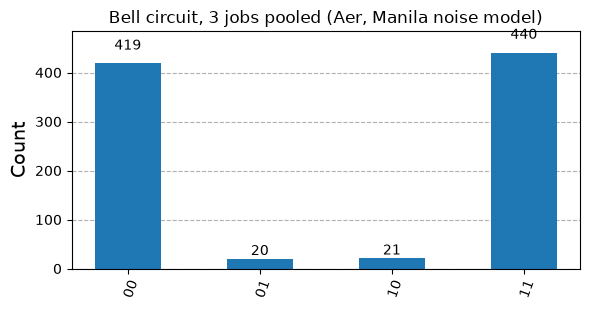

In [23]:
fig = plot_histogram(dict(pooled_counts), title="Bell circuit, 3 jobs pooled (Aer, Manila noise model)", figsize=(6, 3.2))
fig

### Practice 7.6 — Marginal of a GHZ result

From `ghz_bits` (the noisy GHZ result above) build

- `ex6_q02`: the counts of classical bits 0 and 2 only (a dictionary with 2-character keys),
- `ex6_p_agree`: the fraction of shots in which bits 0 and 2 are equal.

In [ ]:
ex6_q02 = None       # TODO
ex6_p_agree = None   # TODO

In [ ]:
# Run this cell to check your answer
assert ex6_q02 == marginal_distribution(ghz_counts, indices=[0, 2])
_agree = sum(v for k, v in ghz_counts.items() if k[-1] == k[-3]) / ghz_bits.num_shots
assert abs(ex6_p_agree - _agree) < 1e-12
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex6_q02 = ghz_bits.slice_bits([0, 2]).get_counts()
ex6_p_agree = (ex6_q02.get("00", 0) + ex6_q02.get("11", 0)) / ghz_bits.num_shots
```

`slice_bits([0, 2])` and `marginal_distribution(counts, indices=[0, 2])` agree. For an ideal GHZ state the two bits always agree; the fake backend's noise model produces a few disagreeing shots.

</details>

### Practice 7.7 — An ⟨XX⟩ estimate with the Sampler

`ex7_state` prepares $\cos(\pi/6)\,|00\rangle + \sin(\pi/6)\,|11\rangle$, for which $\langle X\otimes X\rangle = \sin(\pi/3) \approx 0.866$.
Build `ex7_qc`: a copy of `ex7_state` with the basis change needed to read $X\otimes X$, then `measure_all()`. Run it with `ideal_sampler` (a seeded `SamplerV2` on `AerSimulator()`) and 4000 shots, and store the estimate of ⟨XX⟩ in `ex7_xx`.

In [ ]:
ex7_state = QuantumCircuit(2)
ex7_state.ry(np.pi / 3, 0)
ex7_state.cx(0, 1)

ex7_qc = None   # TODO: copy, rotate basis, measure_all
ex7_xx = None   # TODO: estimate of <XX> from the counts

In [ ]:
# Run this cell to check your answer
assert ex7_qc is not None and ex7_qc.count_ops().get("measure", 0) == 2
_exact = Statevector(ex7_state).expectation_value(SparsePauliOp("XX")).real
assert abs(ex7_xx - _exact) < 0.05, f"estimate {ex7_xx} vs exact {_exact}"
assert abs(ex7_xx - 1.0) > 0.05, "without the basis change you measured <ZZ> = 1"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex7_state = QuantumCircuit(2)
ex7_state.ry(np.pi / 3, 0)
ex7_state.cx(0, 1)

ex7_qc = ex7_state.copy()
ex7_qc.h([0, 1])                     # X basis -> Z basis on both qubits
ex7_qc.measure_all()
ex7_counts = ideal_sampler.run([ex7_qc], shots=4000).result()[0].data.meas.get_counts()
ex7_xx = sampled_expectation_value(ex7_counts, "ZZ")
```

$H$ maps the $X$ eigenbasis to the $Z$ eigenbasis, so after `h` on both qubits the parity of the measured bits estimates $\langle X\otimes X\rangle$. Without the rotation you get $\langle Z\otimes Z\rangle = 1$ for this state. The Estimator performs the same basis change internally.

</details>

Q7.6. A Sampler PUB sweeps a one-parameter circuit over 5 angles with `shots=400`. `bits = result[0].data.meas`. Which statement is correct?

A. `bits.num_shots` is 2000 and `bits.shape` is `()`.

B. `bits.get_counts()` raises an error because a location is required.

C. `bits.get_counts(4)` returns the counts of the last angle, and `bits.get_counts()` adds up all five settings.

D. `result[4]` holds the counts of the last angle.

<details>
<summary>Show answer</summary>

Answer: C

One PUB gives one `PubResult`; the sweep lives in the `BitArray` shape `(5,)`, with `num_shots` = 400 per setting. `get_counts(loc)` picks one setting and `get_counts()` merges all of them, which is easy to misread as a single experiment. `result[4]` (D) would be the fifth PUB and raises `IndexError` here.

</details>

<a id="s7-core-83"></a>

## Section review — exam-style questions

First pass: answer the unmarked questions. Items labelled **Optional extension** or **Deeper API practice** are a separate second pass; they are not prerequisites for moving to the next notebook.

Answer first, then open the fold. Single answer unless the question says Select two.

Q7.7. You saved the ID of a job submitted yesterday. Which code retrieves its result in a new kernel?

A.

```python
service = QiskitRuntimeService()
result = service.job(job_id).result()
```

B.

```python
service = QiskitRuntimeService()
result = service.jobs(job_id=job_id)[0].result()
```

C.

```python
service = QiskitRuntimeService()
result = service.get_job(job_id).result()
```

D.

```python
result = RuntimeJobV2(job_id).result()
```

<details>
<summary>Show answer</summary>

Answer: A

`QiskitRuntimeService.job(job_id)` returns a `RuntimeJobV2`, and `.result()` fetches the stored result. `service.jobs()` has no `job_id` filter (B raises `TypeError`), there is no `get_job` method (C), and the `RuntimeJobV2` constructor needs a backend, an API client and a service, not just an ID (D); you get the object from `run()` or `service.job()`.

</details>

Q7.8. Which call returns the five most recent finished jobs that ran on `ibm_torino`?

A. `service.jobs(limit=5, backend_name="ibm_torino", pending=True)`

B. `service.jobs(limit=5, backend="ibm_torino", status="DONE")`

C. `service.jobs(5, "ibm_torino")`

D. `service.jobs(limit=5, backend_name="ibm_torino", pending=False)`

<details>
<summary>Show answer</summary>

Answer: D

`pending=False` keeps jobs in `DONE`, `CANCELLED` or `ERROR`; `pending=True` (A) keeps queued and running jobs. The keyword is `backend_name`, and there is no `status` filter (B). In C the second positional argument is `skip`, not the backend name.

</details>

Q7.9. Which two strings can `RuntimeJobV2.status()` return? (Select two.)

A. `'COMPLETED'`

B. `'QUEUED'`

C. `'PENDING'`

D. `'FAILED'`

E. `'CANCELLED'`

<details>
<summary>Show answer</summary>

Answer: B, E

The complete set is `'INITIALIZING'`, `'QUEUED'`, `'RUNNING'`, `'CANCELLED'`, `'DONE'` and `'ERROR'`. `Completed` and `Failed` are the service's words, mapped to `'DONE'` and `'ERROR'`; `Pending` is the Platform UI label for a queued job.

</details>

Q7.10. A job stays queued for the entire 30-second wait. What happens when this line runs?

```python
res = job.result(timeout=30)
```

A. After 30 s it returns `None`.

B. After 30 s it raises `RuntimeJobTimeoutError`; the job stays in the queue.

C. After 30 s it cancels the job and raises `RuntimeInvalidStateError`.

D. It returns immediately with a partial result.

<details>
<summary>Show answer</summary>

Answer: B

`result(timeout=...)` waits through `wait_for_final_state(timeout)`, which raises `RuntimeJobTimeoutError` when the time is up. Nothing is cancelled, so you can call `result()` again later. `RuntimeInvalidStateError` is raised when you ask for the result of a job that was cancelled.

</details>

Q7.11. What does this code print?

```python
qc = QuantumCircuit(3)
qc.x(1)
qc.measure_all()
counts = SamplerV2(mode=AerSimulator()).run([qc], shots=100).result()[0].data.meas.get_counts()
print(counts)
```

A. `{'100': 100}`

B. `{'001': 100}`

C. `{'010': 100}`

D. `{'2': 100}`

<details>
<summary>Show answer</summary>

Answer: C

Qubit 1 is measured into classical bit 1, the middle character of a 3-bit little-endian string. For `x(0)` the answer would be `'001'`, for `x(2)` it would be `'100'`. `get_counts()` keys are bitstrings; integer keys come from `get_int_counts()` (which would give `{2: 100}`, not the string `'2'`).

</details>

Q7.12. A circuit has registers `a` (1 bit, always reads `1`) and `b` (2 bits, always reads `00`), added in that order. What does `result[0].join_data(["a", "b"]).get_counts()` return for 50 shots?

A. `{'001': 50}`

B. `{'100': 50}`

C. `{'1': 50, '00': 50}`

D. `{'a1b00': 50}`

<details>
<summary>Show answer</summary>

Answer: A

`join_data` concatenates the listed registers into one `BitArray`; the first name supplies the least significant (right-most) bits. So `a` gives the last character `1` and `b` the leading `00`. `join_data(["b", "a"])` would give `'100'`.

</details>

Q7.13. You know the ID of a session that is still active and want to send one more job into it from a new kernel. Which code is correct?

A.

```python
session = Session(service=service, session_id=sid)
sampler = SamplerV2(session=session)
```

B.

```python
session = service.session(sid)
sampler = SamplerV2(mode=session)
```

C.

```python
session = Session.from_id(sid, service)
sampler = SamplerV2(mode=session)
```

D.

```python
session = Session.from_id(sid)
sampler = SamplerV2(backend=session)
```

<details>
<summary>Show answer</summary>

Answer: C

`Session.from_id(session_id, service)` is a classmethod that needs both the ID and a `QiskitRuntimeService`; the primitive then takes `mode=session`. The `Session` constructor has no `service`/`session_id` arguments and primitives no longer accept `session=` (A); there is no `service.session()` (B); `from_id` without a service fails and primitives take `mode=`, not `backend=` (D).

</details>

Q7.14. A session reached its `max_time`. What does `session.status()` return?

A. `'Closed'`

B. `'DONE'`

C. `'In progress, not accepting new jobs'`

D. `'Pending'`

<details>
<summary>Show answer</summary>

Answer: A

`session.status()` returns `'Pending'`, `'In progress, accepting new jobs'`, `'In progress, not accepting new jobs'` or `'Closed'`; a session whose maximum time expired, or that was closed explicitly, is `'Closed'`. `'DONE'` is a job status.

</details>

Q7.15. Which snippet correctly stores a `PrimitiveResult` in `out.json` so that it can be reconstructed later?

A.

```python
with open("out.json", "w") as f:
    json.dump(result, f)
```

B.

```python
with open("out.json", "w") as f:
    json.dump(result, f, cls=RuntimeDecoder)
```

C.

```python
with open("out.json", "w") as f:
    f.write(str(result))
```

D.

```python
with open("out.json", "w") as f:
    json.dump(result, f, cls=RuntimeEncoder)
```

<details>
<summary>Show answer</summary>

Answer: D

Writing needs the encoder: `json.dump(result, f, cls=RuntimeEncoder)`; reading uses `json.load(f, cls=RuntimeDecoder)`. The default encoder raises `TypeError: Object of type PrimitiveResult is not JSON serializable` (A). A decoder class cannot encode (B). `str(result)` (C) is only a summary (`BitArray(<shape=(), num_shots=..., num_bits=...>)`) and loses the samples.

</details>

Q7.16. What does this code print?

```python
from qiskit.result import sampled_expectation_value
print(sampled_expectation_value({"01": 100}, "ZI"))
```

A. `-1.0`

B. `0.0`

C. `0.5`

D. `1.0`

<details>
<summary>Show answer</summary>

Answer: D

In `"ZI"` the `Z` acts on qubit 1 (little-endian labels). In `'01'` bit 1 is the left character, `0`, so the eigenvalue is $+1$. With `"IZ"` the `Z` would act on bit 0 = `1`, giving $-1$ (A).

</details>

Q7.17. An Estimator PUB has a circuit with one parameter, observables of shape `(2, 1)` and parameter values of shape `(4, 1)`. What is `result[0].data.evs.shape`?

A. `(4,)`

B. `(2, 4)`

C. `(8,)`

D. `(2, 1)`

<details>
<summary>Show answer</summary>

Answer: B

The parameter array of shape `(4, 1)` has one value per set, so its broadcast shape is `(4,)`. Broadcasting `(2, 1)` with `(4,)` gives `(2, 4)`: every observable is evaluated for every parameter set. Shapes are not flattened (C).

</details>

Q7.18. Which two statements about monitoring Runtime jobs are true? (Select two.)

A. `job.usage_estimation` returns a dictionary with the key `'quantum_seconds'`.

B. `job.done()` returns `True` for a job in `'ERROR'`, because the job has ended.

C. `job.metrics()` returns a dictionary that includes `'timestamps'` for created, running and finished.

D. `job.queue_position()` returns the job's current place in the queue.

E. `job.logs()` streams output while the job is still running.

<details>
<summary>Show answer</summary>

Answer: A, C

`usage_estimation` is a property returning `{'quantum_seconds': ...}` and `metrics()` includes `timestamps` and `usage`. `done()` is `True` only for `'DONE'` (B). `RuntimeJobV2` has no `queue_position()` method (D). `logs()` is available only after the job finishes (E).

</details>

Q7.19. `job = SamplerV2(mode=AerSimulator()).run([qc])` has finished. What does `print(job.status())` show?

> **Deeper API practice — optional on the first pass.** Knowing which job class you are using is useful; this exact printed enum representation is deeper local-mode practice.

A. `DONE`

B. `JobStatus.DONE`

C. `COMPLETED`

D. `job has successfully run`

<details>
<summary>Show answer</summary>

Answer: B

In local testing mode `run()` returns a `LocalRuntimeJob`, a subclass of `PrimitiveJob`, whose `status()` is the enum `JobStatus.DONE`; printing an enum member shows `JobStatus.DONE`. The plain string `DONE` (A) is what a `RuntimeJobV2` on IBM Quantum returns. D is `JobStatus.DONE.value`.

</details>

## Cheat sheet

Use this as a reference. It includes optional APIs as well as the core workflow; it is not a list of details to memorise in one pass.

Result anatomy

| Object | Access | Key facts |
|---|---|---|
| `PrimitiveResult` | `job.result()` | list-like, one entry per PUB; `.metadata` (e.g. `{'version': 2}`) |
| `SamplerPubResult` / `PubResult` | `result[i]` | `.data` (`DataBin`), `.metadata` (`shots`, `circuit_metadata`, ...); Sampler adds `join_data(names)` |
| `DataBin` | `result[i].data` | Sampler: one `BitArray` per classical register (`.meas` after `measure_all()`, `.c` for `QuantumCircuit(n, n)`); Estimator: `.evs`, `.stds` |
| `BitArray` | `data.<reg>` | `get_counts(loc=None)`, `get_int_counts()`, `get_bitstrings()`, `num_shots` (per setting), `num_bits`, `shape`, `slice_bits()`, `slice_shots()`, `postselect()`, `expectation_values()`, `BitArray.concatenate_shots()` |

Retrieve

| Task | Code |
|---|---|
| save / load | `json.dump(result, f, cls=RuntimeEncoder)` / `json.load(f, cls=RuntimeDecoder)` |
| account | `QiskitRuntimeService(channel="ibm_quantum_platform", token=..., instance=...)`, `QiskitRuntimeService.save_account(...)` |
| one job | `service.job(job_id)` returns `RuntimeJobV2`; `service.delete_job(job_id)` removes it permanently |
| many jobs | `service.jobs(limit=10, skip, backend_name, pending, program_id, instance, job_tags, session_id, created_after, created_before, descending=True)`; tag jobs with `options.environment.job_tags` |
| session again | `job.session_id`, `Session.from_id(session_id, service)`, `service.jobs(session_id=...)` |
| session info | `details()` keys: `id, backend_name, interactive_timeout, max_time, active_timeout, state, accepting_jobs, last_job_started, last_job_completed, started_at, closed_at, activated_at, mode, usage_time`; `status()`: `Pending` / `In progress, accepting new jobs` / `In progress, not accepting new jobs` / `Closed`; `usage()` |

Monitor (`RuntimeJobV2`)

| Item | Value |
|---|---|
| `status()` strings | `INITIALIZING, QUEUED, RUNNING, CANCELLED, DONE, ERROR` (service: Queued, Running, Completed, Failed, Cancelled) |
| final states | `DONE, CANCELLED, ERROR` (`in_final_state()`); `done()` only for `DONE` |
| waiting | `result(timeout=)`, `wait_for_final_state(timeout=)` raise `RuntimeJobTimeoutError` (client-side wait); `result()` on failed job: `RuntimeJobFailureError`; job stopped at its maximum execution time: `RuntimeJobMaxTimeoutError`; cancelled job: `RuntimeInvalidStateError` |
| information | `job_id()`, `error_message()`, `metrics()` (`timestamps`, `usage`), `usage()`, `usage_estimation` (`quantum_seconds`), `logs()`, `creation_date`, `session_id`, `tags`, `update_tags()`, `backend()`, `properties()`, `cancel()` |
| local jobs | `JobStatus` enum (`INITIALIZING, QUEUED, VALIDATING, RUNNING, CANCELLED, DONE, ERROR`); `result()` has no `timeout` |

Analyze

| Task | Code |
|---|---|
| bit order | right-most character = classical bit 0; Pauli `"ZI"` = Z on qubit 1 |
| marginals | `bits.slice_bits([0, 2])`, `marginal_distribution(counts, indices=[0, 2])` |
| ⟨Z…Z⟩ from counts | `sampled_expectation_value(counts, "ZZ")`, `bits.expectation_values([...])` (diagonal only) |
| pool jobs | `Counter(c1) + Counter(c2)`, `BitArray.concatenate_shots([b1, b2])` |

## Sources and further reading

- Qiskit Advocate KR study notebooks, Section 7: [`1_Retrieve_Experiment_Results_ko.ipynb`, `2_Monitor_Jobs_KR.ipynb`, `sampler_result.json`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_7_Retrieve_Analyze_Results)
- QAMP 2025 textbook: [qiskit_2x_certification_exam_tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial) (`Section_7_Retrieve_Analyze_Results`)
- IBM Quantum documentation: [Save and retrieve jobs](https://quantum.cloud.ibm.com/docs/guides/save-jobs), [Monitor or cancel a job](https://quantum.cloud.ibm.com/docs/guides/monitor-job), [Primitive inputs and outputs](https://quantum.cloud.ibm.com/docs/guides/primitive-input-output)
- API reference: [`QiskitRuntimeService`](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/qiskit-runtime-service), [`RuntimeJobV2`](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/runtime-job-v2), [`Session`](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/session), [`qiskit.primitives` containers](https://quantum.cloud.ibm.com/docs/api/qiskit/primitives), [`qiskit.result`](https://quantum.cloud.ibm.com/docs/api/qiskit/result)
- Versions used: qiskit 2.0.3, qiskit-ibm-runtime 0.40.1, qiskit-aer 0.17.1 (method names, status strings and `details()` keys were checked against this installed source).

First-pass workflow review also consulted the open-source [Quantum Tokyo certification practice notebooks](https://github.com/quantum-tokyo/qiskit-certification-prep): execution-mode selection (Section 4), ISA preparation and default shots (Sections 5–6), and past-job retrieval (Section 7). Their questions were used as a style/reference check, not copied here; the official guide remains the scope reference.

## References

Version checked: qiskit 2.0.3, qiskit-aer 0.17.1 and qiskit-ibm-runtime 0.40.1. Local runs use `SamplerV2` / `EstimatorV2` on `AerSimulator`.

- [IBM certification page / official objectives](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400)
- [IBM announcement for the v2.X certification](https://www.ibm.com/quantum/blog/qiskit-v2x-developer-certification)
- [Qiskit SDK 2.0 API index](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/index)
- [qiskit-ibm-runtime 0.39 API index](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40)
- [RuntimeJobV2 (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/runtime-job-v2)
- [QiskitRuntimeService (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/qiskit-runtime-service)
- [Session (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/session)
- [Primitives results (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/primitives)
- [qiskit.result (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/result)

### Community repositories

- [Qiskit Advocate KR study repository](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94)
- [QAMP 2025 Qiskit 2.x certification tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial)
